In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
# For reproducibility
np.random.seed(42)


In [ ]:
# ------------------------------------------------
# DATASET
# Two features:
# X = Height
# Y = Size
# ------------------------------------------------

In [ ]:
data = np.array([
    # Small group
    [1.8, 2.1],
    [2.0, 2.4],
    [2.2, 1.9],
    [2.4, 2.5],
    [2.6, 2.2],
    [2.8, 2.7],
    [3.0, 2.3],
    [2.5, 1.8],

    # Medium group
    [4.5, 4.8],
    [4.8, 5.2],
    [5.0, 4.5],
    [5.2, 5.5],
    [5.5, 5.0],
    [5.7, 5.7],
    [6.0, 5.2],
    [5.3, 4.7],
    [4.7, 5.6],

    # Big group
    [7.2, 7.5],
    [7.5, 8.0],
    [7.8, 7.2],
    [8.0, 8.5],
    [8.3, 7.8],
    [8.6, 8.7],
    [8.9, 8.1],
    [9.2, 8.8],
    [8.5, 7.4]
])

In [ ]:
df = pd.DataFrame(data, columns=["Height", "Size"])

df.head()

,Height,Size
0,1.8,2.1
1,2.0,2.4
2,2.2,1.9
3,2.4,2.5
4,2.6,2.2


2. Visualize the raw data

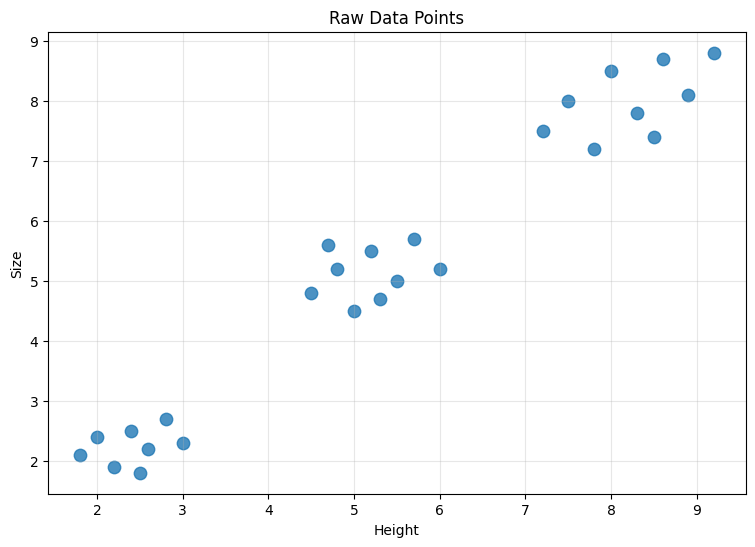

In [ ]:
plt.figure(figsize=(9, 6))

plt.scatter(
    df["Height"],
    df["Size"],
    s=80,
    alpha=0.8
)

plt.xlabel("Height")
plt.ylabel("Size")
plt.title("Raw Data Points")
plt.grid(True, alpha=0.3)

plt.show()

The algorithm does not know that there are Small, Medium and Big groups. It only sees coordinates.

In [ ]:
#Convert DataFrame to NumPy array
X = df[["Height", "Size"]].values

print(X.shape)
print(X)

(26, 2)
[[1.8 2.1]
 [2.  2.4]
 [2.2 1.9]
 [2.4 2.5]
 [2.6 2.2]
 [2.8 2.7]
 [3.  2.3]
 [2.5 1.8]
 [4.5 4.8]
 [4.8 5.2]
 [5.  4.5]
 [5.2 5.5]
 [5.5 5. ]
 [5.7 5.7]
 [6.  5.2]
 [5.3 4.7]
 [4.7 5.6]
 [7.2 7.5]
 [7.5 8. ]
 [7.8 7.2]
 [8.  8.5]
 [8.3 7.8]
 [8.6 8.7]
 [8.9 8.1]
 [9.2 8.8]
 [8.5 7.4]]


In [ ]:
#Choose K
K = 3

In [ ]:
#Initialize centroids manually
centroids = np.array([
    [2.0, 2.0],
    [5.0, 5.0],
    [8.5, 8.0]
])

print("Initial Centroids:")
print(centroids)

Initial Centroids:
[[2.  2. ]
 [5.  5. ]
 [8.5 8. ]]


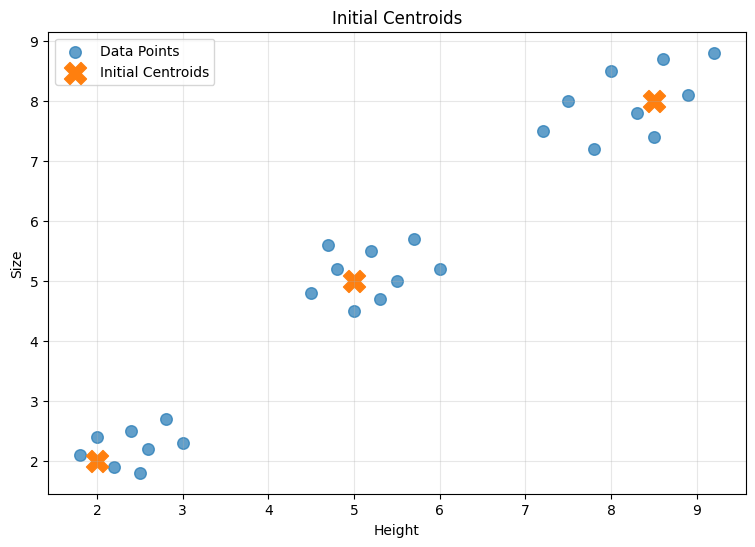

In [ ]:
#Visualize them
plt.figure(figsize=(9, 6))

plt.scatter(
    X[:, 0],
    X[:, 1],
    s=70,
    alpha=0.7,
    label="Data Points"
)

plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    s=250,
    marker="X",
    label="Initial Centroids"
)

plt.xlabel("Height")
plt.ylabel("Size")
plt.title("Initial Centroids")
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

In [ ]:
#Calculate distance manually
point = X[0]

print("Point:", point)

for i, centroid in enumerate(centroids):

    distance = np.sqrt(
        (point[0] - centroid[0])**2 +
        (point[1] - centroid[1])**2
    )

    print(f"Distance from C{i+1}: {distance:.3f}")

Point: [1.8 2.1]
Distance from C1: 0.224
Distance from C2: 4.319
Distance from C3: 8.927


Calculate distances for ALL points

In [ ]:
distances = np.zeros((len(X), K))

for i in range(len(X)):

    for j in range(K):

        distances[i, j] = np.sqrt(
            (X[i, 0] - centroids[j, 0])**2 +
            (X[i, 1] - centroids[j, 1])**2
        )

print(distances)

[[0.2236068  4.31856458 8.92748565]
 [0.4        3.96988665 8.57962703]
 [0.2236068  4.17731971 8.76926451]
 [0.64031242 3.60693776 8.21340368]
 [0.63245553 3.68781778 8.27345152]
 [1.06301458 3.18276609 7.78331549]
 [1.04403065 3.36005952 7.92085854]
 [0.53851648 4.0607881  8.62786184]
 [3.75366488 0.53851648 5.12249939]
 [4.25205833 0.28284271 4.6400431 ]
 [3.90512484 0.5        4.94974747]
 [4.74236228 0.53851648 4.14004831]
 [4.60977223 0.5        4.24264069]
 [5.23259018 0.98994949 3.62353419]
 [5.12249939 1.0198039  3.75366488]
 [4.26380112 0.42426407 4.59673797]
 [4.5        0.67082039 4.49444101]
 [7.56901579 3.33016516 1.39283883]
 [8.1394103  3.90512484 1.        ]
 [7.78973684 3.56089876 1.06301458]
 [8.84590301 4.60977223 0.70710678]
 [8.56329376 4.327817   0.28284271]
 [9.40478602 5.1623638  0.70710678]
 [9.20977741 4.98196748 0.41231056]
 [9.90353472 5.6639209  1.06301458]
 [8.45044378 4.24381903 0.6       ]]


Assign each point to nearest centroid

In [ ]:
labels = np.argmin(distances, axis=1)

print(labels)

[0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 2 2 2 2 2 2 2 2 2]


Visualize the first assignment

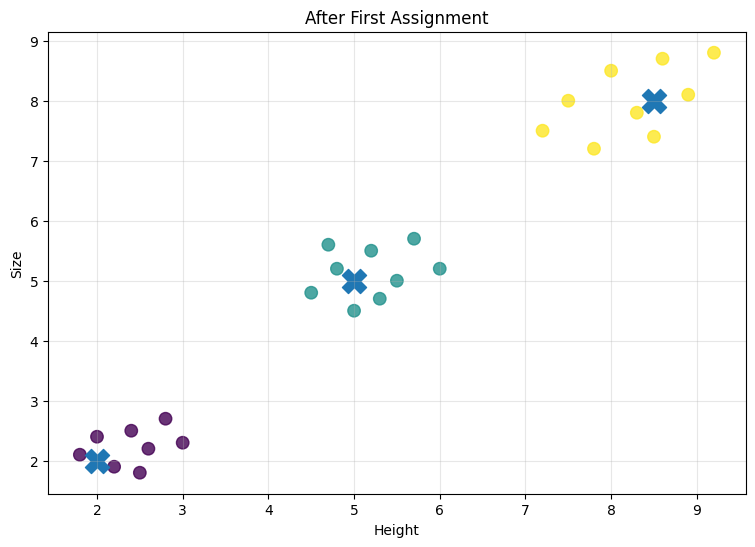

In [ ]:
plt.figure(figsize=(9, 6))

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=labels,
    s=80,
    alpha=0.8
)

plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    marker="X",
    s=300
)

plt.xlabel("Height")
plt.ylabel("Size")
plt.title("After First Assignment")
plt.grid(True, alpha=0.3)

plt.show()

Calculate new centroids

In [ ]:
new_centroids = np.zeros((K, 2))

for cluster in range(K):

    cluster_points = X[labels == cluster]

    new_centroids[cluster] = cluster_points.mean(axis=0)

print("Old Centroids:")
print(centroids)

print("\nNew Centroids:")
print(new_centroids)

Old Centroids:
[[2.  2. ]
 [5.  5. ]
 [8.5 8. ]]

New Centroids:
[[2.4125     2.2375    ]
 [5.18888889 5.13333333]
 [8.22222222 8.        ]]


Visualize centroid movement

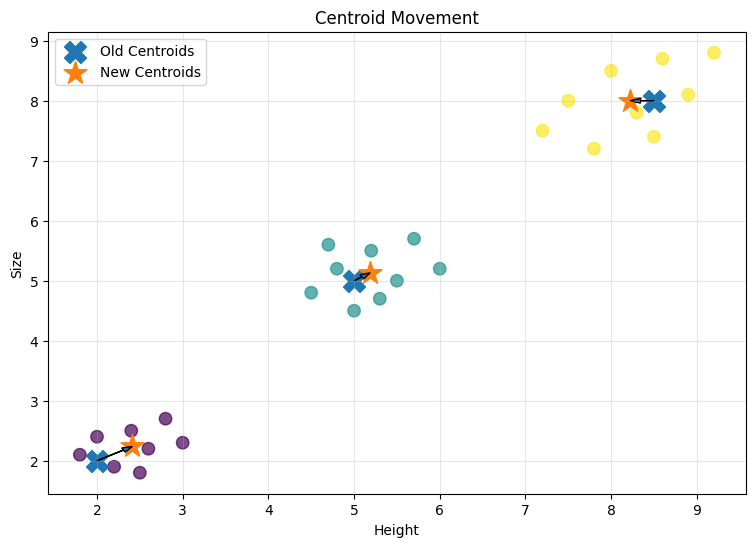

In [ ]:
plt.figure(figsize=(9, 6))

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=labels,
    s=80,
    alpha=0.7
)

# Old centroids
plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    marker="X",
    s=250,
    label="Old Centroids"
)

# New centroids
plt.scatter(
    new_centroids[:, 0],
    new_centroids[:, 1],
    marker="*",
    s=300,
    label="New Centroids"
)

# Draw movement
for old, new in zip(centroids, new_centroids):

    plt.arrow(
        old[0],
        old[1],
        new[0] - old[0],
        new[1] - old[1],
        length_includes_head=True,
        head_width=0.08
    )

plt.xlabel("Height")
plt.ylabel("Size")
plt.title("Centroid Movement")
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

Update the centroids

In [ ]:
centroids = new_centroids

Put everything into a manual K-Means loop


In [ ]:
def manual_kmeans(X, K, initial_centroids, max_iterations=10):

    centroids = initial_centroids.copy()

    history = []
    wcss_history = []

    for iteration in range(max_iterations):

        # --------------------------------
        # STEP 1: Calculate distances
        # --------------------------------

        distances = np.zeros((len(X), K))

        for i in range(len(X)):

            for j in range(K):

                distances[i, j] = np.sqrt(
                    (X[i, 0] - centroids[j, 0])**2 +
                    (X[i, 1] - centroids[j, 1])**2
                )

        # --------------------------------
        # STEP 2: Assign points
        # --------------------------------

        labels = np.argmin(distances, axis=1)

        # --------------------------------
        # STEP 3: Calculate WCSS
        # --------------------------------

        wcss = 0

        for cluster in range(K):

            cluster_points = X[labels == cluster]

            if len(cluster_points) > 0:

                squared_distances = np.sum(
                    (cluster_points - centroids[cluster])**2,
                    axis=1
                )

                wcss += np.sum(squared_distances)

        wcss_history.append(wcss)

        # Save current state
        history.append(
            (centroids.copy(), labels.copy())
        )

        # --------------------------------
        # STEP 4: Calculate new centroids
        # --------------------------------

        new_centroids = np.zeros((K, 2))

        for cluster in range(K):

            cluster_points = X[labels == cluster]

            if len(cluster_points) > 0:

                new_centroids[cluster] = cluster_points.mean(axis=0)

            else:

                new_centroids[cluster] = centroids[cluster]

        # --------------------------------
        # STEP 5: Check convergence
        # --------------------------------

        if np.allclose(centroids, new_centroids):

            centroids = new_centroids

            print(f"Converged at iteration {iteration + 1}")

            break

        centroids = new_centroids

    return labels, centroids, wcss_history, history

Run our manual K-Means

In [ ]:
initial_centroids = np.array([
    [2.0, 2.0],
    [5.0, 5.0],
    [8.5, 8.0]
])

labels_manual, centroids_manual, wcss_history, history = manual_kmeans(
    X,
    K=3,
    initial_centroids=initial_centroids,
    max_iterations=20
)

Converged at iteration 2


Print the final result

In [ ]:
print("Final Centroids:\n")

for i, centroid in enumerate(centroids_manual):

    print(
        f"Cluster {i+1}: "
        f"({centroid[0]:.3f}, {centroid[1]:.3f})"
    )

print("\nWCSS at each iteration:")

for i, wcss in enumerate(wcss_history):

    print(
        f"Iteration {i+1}: {wcss:.3f}"
    )

Final Centroids:

Cluster 1: (2.413, 2.238)
Cluster 2: (5.189, 5.133)
Cluster 3: (8.222, 8.000)

WCSS at each iteration:
Iteration 1: 14.200
Iteration 2: 11.212


Plot final manual K-Means result

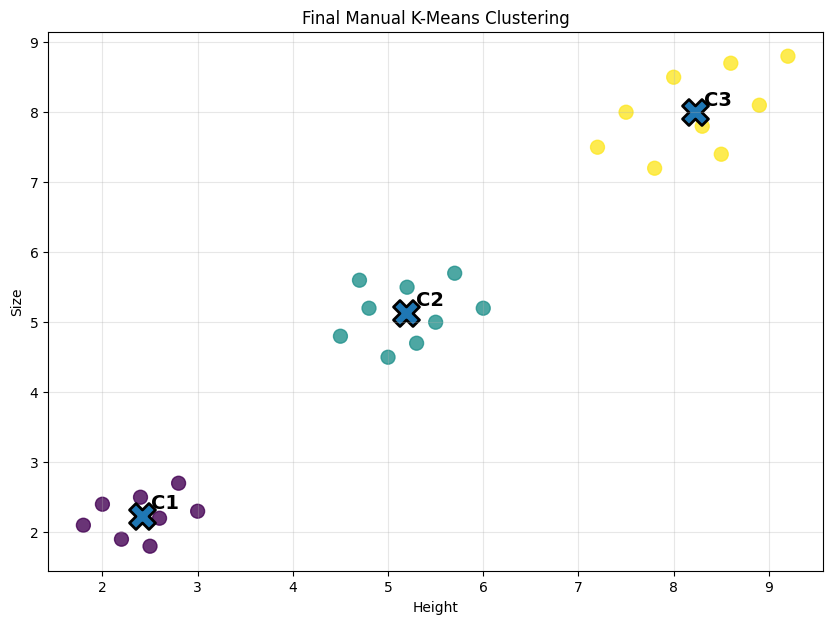

In [ ]:
plt.figure(figsize=(10, 7))

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=labels_manual,
    s=100,
    alpha=0.8
)

plt.scatter(
    centroids_manual[:, 0],
    centroids_manual[:, 1],
    marker="X",
    s=350,
    edgecolor="black",
    linewidth=2
)

for i, centroid in enumerate(centroids_manual):

    plt.text(
        centroid[0] + 0.1,
        centroid[1] + 0.1,
        f"C{i+1}",
        fontsize=14,
        fontweight="bold"
    )

plt.xlabel("Height")
plt.ylabel("Size")
plt.title("Final Manual K-Means Clustering")
plt.grid(True, alpha=0.3)

plt.show()

Plot WCSS vs Iteration

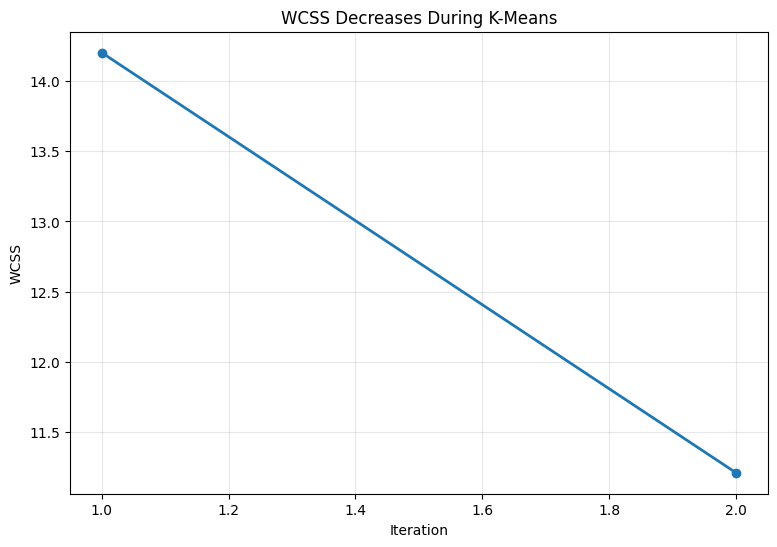

In [ ]:
plt.figure(figsize=(9, 6))

plt.plot(
    range(1, len(wcss_history) + 1),
    wcss_history,
    marker="o",
    linewidth=2
)

plt.xlabel("Iteration")
plt.ylabel("WCSS")
plt.title("WCSS Decreases During K-Means")
plt.grid(True, alpha=0.3)

plt.show()

Draw the actual WCSS distances

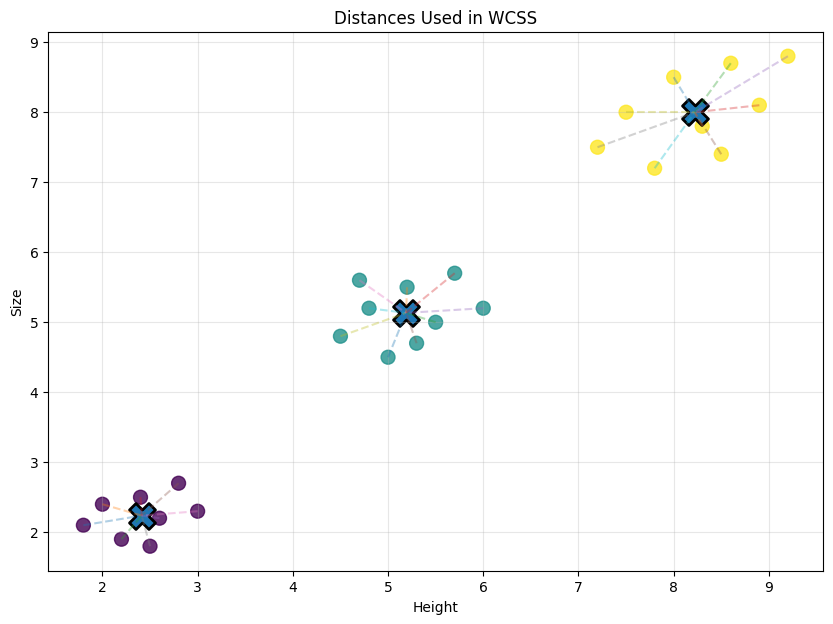

In [ ]:
plt.figure(figsize=(10, 7))

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=labels_manual,
    s=100,
    alpha=0.8
)

plt.scatter(
    centroids_manual[:, 0],
    centroids_manual[:, 1],
    marker="X",
    s=350,
    edgecolor="black",
    linewidth=2
)

# Draw line from every point to its centroid
for i in range(len(X)):

    cluster = labels_manual[i]

    centroid = centroids_manual[cluster]

    plt.plot(
        [X[i, 0], centroid[0]],
        [X[i, 1], centroid[1]],
        linestyle="--",
        alpha=0.35
    )

plt.xlabel("Height")
plt.ylabel("Size")
plt.title("Distances Used in WCSS")
plt.grid(True, alpha=0.3)

plt.show()

Manually calculate WCSS for each cluster

In [ ]:
cluster_wcss = []

for cluster in range(K):

    cluster_points = X[labels_manual == cluster]

    squared_distances = np.sum(
        (cluster_points - centroids_manual[cluster])**2,
        axis=1
    )

    cluster_sum = np.sum(squared_distances)

    cluster_wcss.append(cluster_sum)

    print(f"\nCluster {cluster + 1}")

    print("Squared distances:")

    print(squared_distances)

    print(
        f"Cluster WCSS = {cluster_sum:.3f}"
    )

print("\nTotal WCSS =", sum(cluster_wcss))


Cluster 1
Squared distances:
[0.3940625 0.1965625 0.1590625 0.0690625 0.0365625 0.3640625 0.3490625
 0.1990625]
Cluster WCSS = 1.767

Cluster 2
Squared distances:
[0.58567901 0.15567901 0.43679012 0.1345679  0.1145679  0.58234568
 0.66234568 0.20012346 0.45679012]
Cluster WCSS = 3.329

Cluster 3
Squared distances:
[1.29493827 0.52160494 0.8182716  0.29938272 0.04604938 0.63271605
 0.46938272 1.59604938 0.43716049]
Cluster WCSS = 6.116

Total WCSS = 11.211944444444443


Now do the same thing using Scikit-**Learn** **bold text**

In [ ]:
from sklearn.cluster import KMeans

In [ ]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

kmeans.fit(X)

KMeans(n_clusters=3, n_init=10, random_state=42)

In [ ]:
#Get the cluster labels
labels_sklearn = kmeans.labels_

print(labels_sklearn)

[2 2 2 2 2 2 2 2 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1]


Get the centroids

In [ ]:
centroids_sklearn = kmeans.cluster_centers_

print("Centroids:")

print(centroids_sklearn)

Centroids:
[[5.18888889 5.13333333]
 [8.22222222 8.        ]
 [2.4125     2.2375    ]]


Get WCSS directly

In [ ]:
wcss_sklearn = kmeans.inertia_

print("WCSS =", wcss_sklearn)

WCSS = 11.211944444444443


Visualize Scikit-Learn result

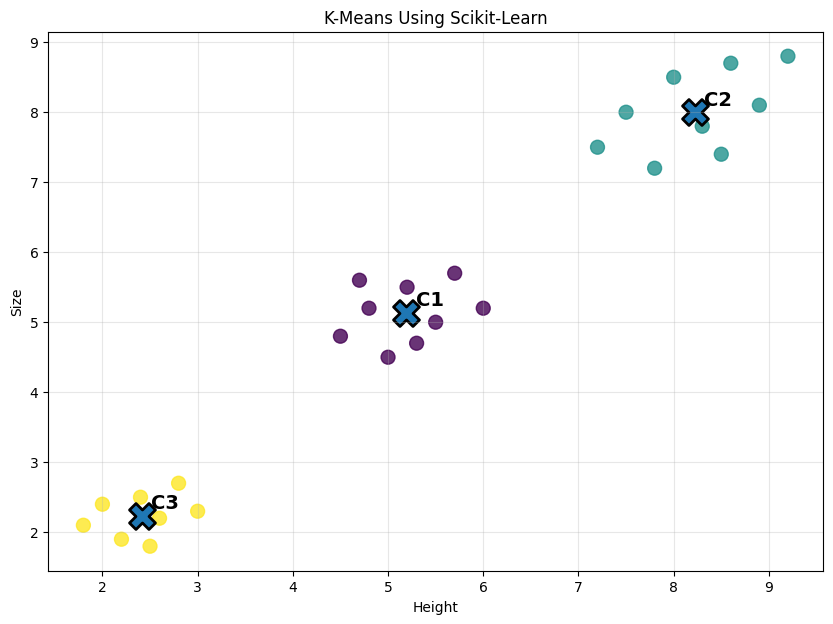

In [ ]:
plt.figure(figsize=(10, 7))

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=labels_sklearn,
    s=100,
    alpha=0.8
)

plt.scatter(
    centroids_sklearn[:, 0],
    centroids_sklearn[:, 1],
    marker="X",
    s=350,
    edgecolor="black",
    linewidth=2
)

for i, centroid in enumerate(centroids_sklearn):

    plt.text(
        centroid[0] + 0.1,
        centroid[1] + 0.1,
        f"C{i+1}",
        fontsize=14,
        fontweight="bold"
    )

plt.xlabel("Height")
plt.ylabel("Size")
plt.title("K-Means Using Scikit-Learn")
plt.grid(True, alpha=0.3)

plt.show()

Visualize Scikit-Learn result

In [ ]:
print("Manual K-Means WCSS:")
print(wcss_history[-1])

print("\nScikit-Learn WCSS:")
print(kmeans.inertia_)

Manual K-Means WCSS:
11.211944444444443

Scikit-Learn WCSS:
11.211944444444443


Elbow Method — WCSS for different K

In [ ]:
wcss_values = []

K_values = range(1, 8)

for k in K_values:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X)

    wcss_values.append(model.inertia_)

Plot it

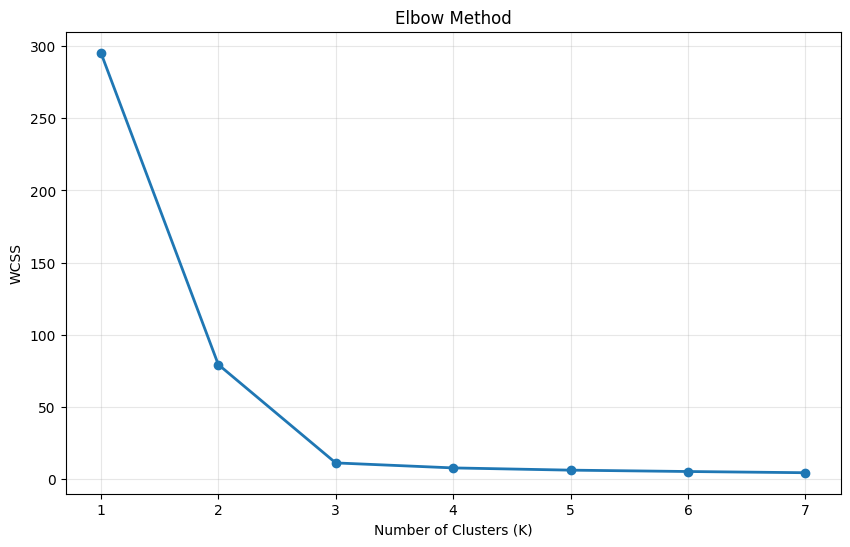

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(
    K_values,
    wcss_values,
    marker="o",
    linewidth=2
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.xticks(K_values)
plt.grid(True, alpha=0.3)

plt.show()

Complete visual comparison

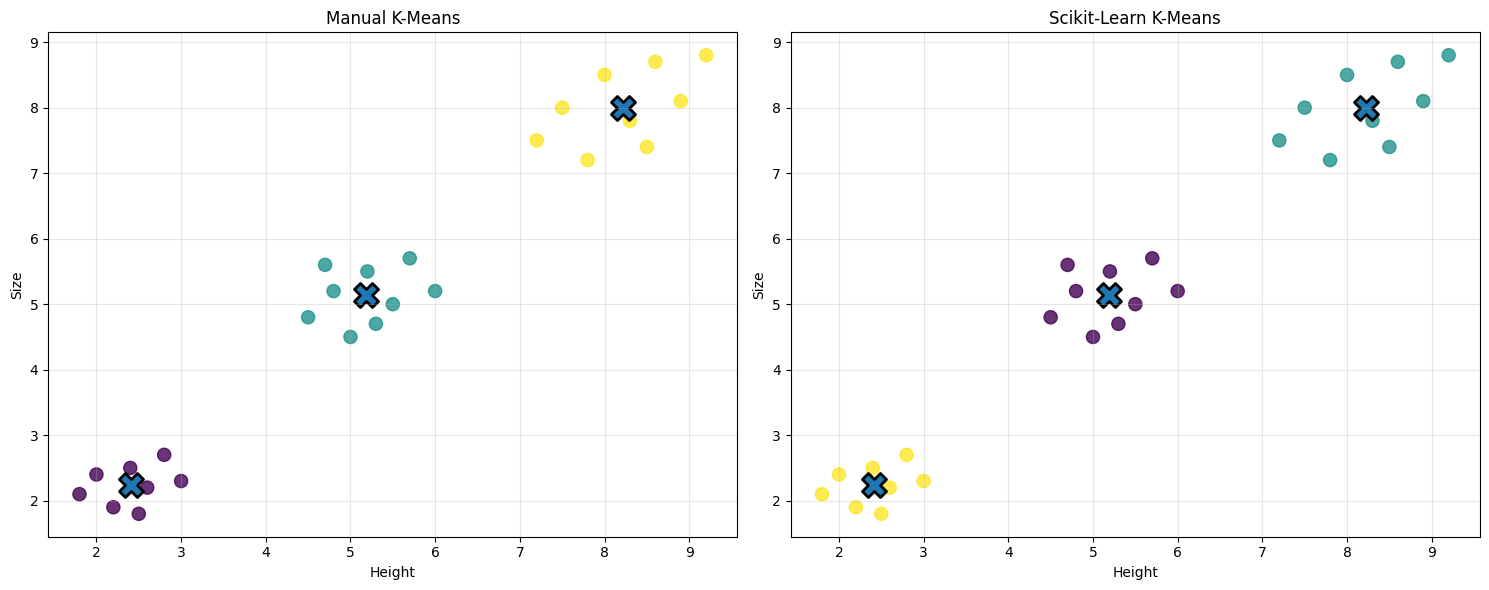

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# -----------------------------
# Manual K-Means
# -----------------------------

axes[0].scatter(
    X[:, 0],
    X[:, 1],
    c=labels_manual,
    s=90,
    alpha=0.8
)

axes[0].scatter(
    centroids_manual[:, 0],
    centroids_manual[:, 1],
    marker="X",
    s=300,
    edgecolor="black",
    linewidth=2
)

axes[0].set_title("Manual K-Means")
axes[0].set_xlabel("Height")
axes[0].set_ylabel("Size")
axes[0].grid(True, alpha=0.3)


# -----------------------------
# Scikit-Learn
# -----------------------------

axes[1].scatter(
    X[:, 0],
    X[:, 1],
    c=labels_sklearn,
    s=90,
    alpha=0.8
)

axes[1].scatter(
    centroids_sklearn[:, 0],
    centroids_sklearn[:, 1],
    marker="X",
    s=300,
    edgecolor="black",
    linewidth=2
)

axes[1].set_title("Scikit-Learn K-Means")
axes[1].set_xlabel("Height")
axes[1].set_ylabel("Size")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()